In [1]:

from pathlib import Path
import requests

# Dossier de destination
dossier = Path("D:/GeoMobility360_AI/data/raw/")
dossier.mkdir(parents=True, exist_ok=True)

# API et paramètres
url = "https://geo.api.gouv.fr/communes"

parametres = {
    "codeRegion": "11",
    "format": "geojson",
    "geometry": "contour"
}

# Téléchargement
reponse = requests.get(url, params=parametres, timeout=120)
reponse.raise_for_status()

# Enregistrement
fichier = dossier / "communes_idf.geojson"
fichier.write_bytes(reponse.content)

print("Fichier téléchargé :", fichier)


Fichier téléchargé : D:\GeoMobility360_AI\data\raw\communes_idf.geojson


In [2]:

import os

# Corriger les variables d'environnement
os.environ["OMP_NUM_THREADS"] = "4"
os.environ["NUMEXPR_NUM_THREADS"] = "4"

# Vérifier les valeurs
print("OMP :", os.environ["OMP_NUM_THREADS"])
print("NUMEXPR :", os.environ["NUMEXPR_NUM_THREADS"])

# Importer les bibliothèques
import pandas as pd
import geopandas as gpd

print("Pandas :", pd.__version__)
print("GeoPandas :", gpd.__version__)


OMP : 4
NUMEXPR : 4
Pandas : 2.2.2
GeoPandas : 1.0.1


## 2. Explorer les données

In [4]:
communes = gpd.read_file("D:/GeoMobility360_AI/data/raw/communes_idf.geojson")

print("Dimensions :", communes.shape)
print("Colonnes :", communes.columns.tolist())
print("Projection :", communes.crs)

communes.head()


Skipping field codesPostaux: unsupported OGR type: 5


Dimensions : (1266, 8)
Colonnes : ['nom', 'code', 'codeDepartement', 'siren', 'codeEpci', 'codeRegion', 'population', 'geometry']
Projection : EPSG:4326


,nom,code,codeDepartement,siren,codeEpci,codeRegion,population,geometry
0,Paris,75056,75,217500016,200054781,11,2103778,"POLYGON ((2.35198 48.90148, 2.35524 48.90155, ..."
1,Achères-la-Forêt,77001,77,217700012,200072346,11,1191,"POLYGON ((2.55546 48.37128, 2.55603 48.37126, ..."
2,Amillis,77002,77,217700020,200090504,11,830,"POLYGON ((3.12671 48.7053, 3.12605 48.70543, 3..."
3,Amponville,77003,77,217700038,200023240,11,349,"POLYGON ((2.503 48.2851, 2.50287 48.28591, 2.5..."
4,Andrezel,77004,77,217700046,200070779,11,336,"POLYGON ((2.76939 48.60338, 2.76667 48.60525, ..."


## 3. Contrôler la qualité

In [5]:

# Valeurs manquantes
print(communes.isna().sum())

# Codes géographiques en double
print("Doublons :", communes["code"].duplicated().sum())

# Géométries absentes
print("Géométries manquantes :", communes.geometry.isna().sum())


nom                0
code               0
codeDepartement    0
siren              0
codeEpci           0
codeRegion         0
population         0
geometry           0
dtype: int64
Doublons : 0
Géométries manquantes : 0


## 4. Afficher la première carte

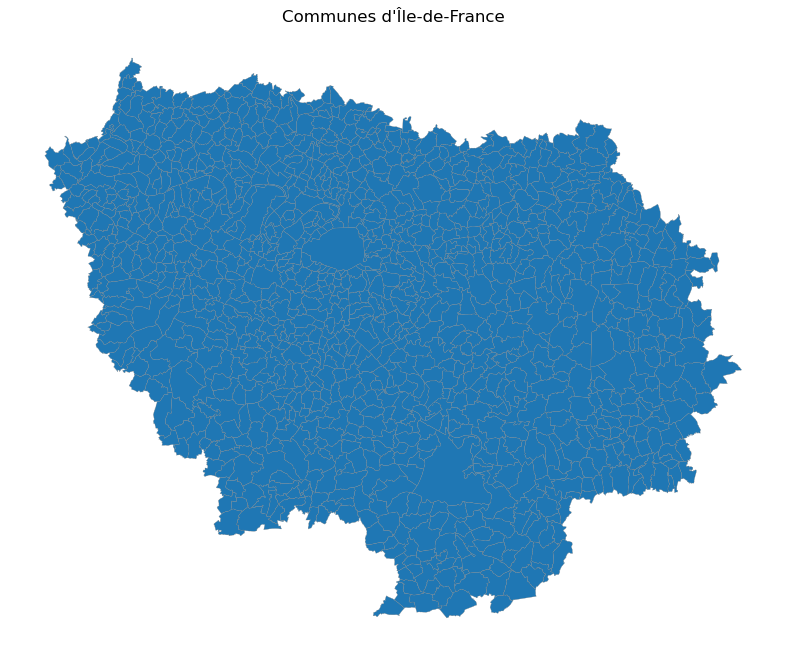

In [6]:

import matplotlib.pyplot as plt

communes.plot(
    figsize=(10, 8),
    edgecolor="grey",
    linewidth=0.2
)

plt.title("Communes d'Île-de-France")
plt.axis("off")
plt.show()
